# 03 · LightGBM

**Objetivo:** entrenar un modelo de aprendizaje automático global (un solo modelo para las 600 series) y comprobar si supera al mejor modelo simple del notebook 02, que es la referencia: **SES + índice semanal** (RMSSE de 0,742 en validación y 0,769 en test; MAE de 1,036 y 1,008).

**Por qué LightGBM:** es un modelo de árboles de gradiente, rápido en CPU, que maneja bien variables de distinto tipo y valores faltantes, y es el enfoque con el que se obtuvieron los mejores resultados en la competencia M5.

**Estrategia directa:** en lugar de pronosticar un día y usar ese pronóstico para el siguiente (estrategia recursiva, que acumula errores), se entrena **un solo modelo** que predice la venta de cualquier día del horizonte. Cada fila del conjunto de entrenamiento representa una serie, un origen (el día desde el que se pronostica) y un día del horizonte (de 1 a 28 días hacia adelante); la variable `horizonte` le indica al modelo cuán lejos está el día a predecir.

**Protocolo (el del notebook 01):**
- Los hiperparámetros se eligen en la **ventana de validación**, entrenando solo con datos anteriores a su origen.
- El modelo elegido se **reentrena** con los datos hasta el origen del test y se evalúa en el test **una sola vez**.
- Métricas: RMSSE y MAE.

## 1. Setup y datos

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import ensure_m5, load_calendar, load_prices, load_sales, day_columns, sample_series, SEED
from src.metrics import evaluar, rmsse
from src.forecasting import (
    ventanas, clasificar_demanda, guardar_resultados,
    pronostico_media_movil, ses_semanal,
)
from src.gbm import (
    HORIZONTE, preparar_contexto, construir_dataset, construir_varios, a_matriz,
    verificar_sin_fuga, entrenar, reentrenar,
)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)

In [2]:
carpeta = ensure_m5()
calendario = load_calendar(carpeta)
precios = load_prices(carpeta)
ventas = load_sales(carpeta)
dias = day_columns(ventas)

muestra = sample_series(ventas, n_per_store=60, seed=SEED)
ctx = preparar_contexto(muestra, calendario, precios, dias)

Y = ctx["Y"]
n, T = Y.shape
H = HORIZONTE
V = ventanas(T, H)
o_val = V["validación"][0] - 1   # origen de la ventana de validación
o_test = V["test"][0] - 1        # origen de la ventana de test
print(f"Series: {n} | días: {T} | origen de validación: {o_val} | origen de test: {o_test}")

Series: 600 | días: 1941 | origen de validación: 1885 | origen de test: 1913


## 2. Variables

Todas las variables de una fila se conocen **en el origen** o se sabían de antemano para el día a pronosticar. Nunca se usan ventas posteriores al origen.

| Grupo | Variables | Qué representan |
|---|---|---|
| Ventas recientes | `lag_0` a `lag_6` | Ventas de cada uno de los últimos 7 días (`lag_0` es el día del origen) |
| Niveles | `media_7`, `media_14`, `media_28`, `media_56`, `media_91`, `tendencia` | Promedios de ventas en distintas ventanas y cociente entre `media_28` y `media_91` |
| Intermitencia | `desvio_28`, `ceros_28`, `ceros_91`, `dias_desde_venta`, `media_con_venta_91` | Variabilidad, proporción de días sin ventas, días desde la última venta y venta media en los días con ventas |
| Antigüedad | `edad` | Días desde la primera venta de la serie |
| Mismo día de la semana | `lag_mismo_dia`, `prom_mismo_dia_4s` | Venta del mismo día de la semana anterior y promedio de las últimas 4 semanas, para cada día del horizonte |
| Horizonte | `horizonte` | Cuántos días hacia adelante está el día a pronosticar (1 a 28) |
| Calendario del día a pronosticar | `dia_semana`, `dia_mes`, `mes`, `es_navidad`, `tipo_evento`, `snap` | Día de la semana y del mes, mes, marca del 25 de diciembre, tipo de evento y si es día SNAP en el estado de la tienda |
| Precio del día a pronosticar | `precio_obj`, `precio_rel_origen`, `precio_rel_mediana` | Precio, y relativo al precio del origen y a la mediana histórica de la serie. Se asume, como en el protocolo, que los precios futuros se conocen |
| Serie | `tienda`, `departamento`, `categoria` | Variables categóricas |

**Prueba anti-fuga:** se alteran al azar las ventas posteriores al origen y se comprueba que las variables no cambian. Es la comprobación más importante de este tipo de pipelines, porque un error de índices que "mire el futuro" haría que el modelo parezca excelente en la evaluación y falle en la práctica.

In [3]:
print("Las variables no cambian al alterar las ventas posteriores al origen:", verificar_sin_fuga(ctx, o_val))

X_demo, y_demo, idx_demo = construir_dataset(ctx, o_val)
print(f"Filas del conjunto de un origen: {len(X_demo):,} = {len(idx_demo)} series × {H} días")
X_demo.head(3)

Las variables no cambian al alterar las ventas posteriores al origen: True
Filas del conjunto de un origen: 16,800 = 600 series × 28 días


,lag_0,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,media_7,media_14,media_28,media_56,media_91,desvio_28,ceros_28,ceros_91,dias_desde_venta,media_con_venta_91,tendencia,edad,lag_mismo_dia,prom_mismo_dia_4s,horizonte,dia_semana,dia_mes,mes,es_navidad,tipo_evento,snap,precio_obj,precio_rel_origen,precio_rel_mediana,tienda,departamento,categoria
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,190.0,NaN,0.0,1436.0,0.0,0.0,1,2,28,3,0,ninguno,0,5.88,1.0,1.0,CA_1,HOBBIES_1,HOBBIES
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,190.0,NaN,0.0,1436.0,0.0,0.0,2,3,29,3,0,ninguno,0,5.88,1.0,1.0,CA_1,HOBBIES_1,HOBBIES
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,190.0,NaN,0.0,1436.0,0.0,0.0,3,4,30,3,0,ninguno,0,5.88,1.0,1.0,CA_1,HOBBIES_1,HOBBIES


## 3. Conjuntos de entrenamiento

Los orígenes de entrenamiento son **semanales y caen el mismo día de la semana que el origen a evaluar**, como ocurre en los orígenes de validación y test (se separan 28 días). Se usan los últimos `N_ORIGENES` orígenes (52 equivalen a un año), porque las ventas crecen con el tiempo y lo reciente describe mejor la demanda actual.

Para que el modelo no vea el futuro, los días a predecir de cualquier origen de entrenamiento terminan antes del origen de evaluación:
- **Validación:** orígenes hasta el día `o_val − 28`.
- **Test:** orígenes hasta el día `o_test − 28` (que incluyen los datos de la ventana de validación).

La **parada temprana** (dejar de agregar árboles cuando el error deja de mejorar) necesita un conjunto de control. Se reservan para eso los 4 orígenes de entrenamiento más recientes, que no se usan para entrenar en la etapa de validación. No se usa la ventana de validación para eso, para que sus métricas sean una medida honesta del desempeño.

In [4]:
N_ORIGENES = 52   # orígenes semanales de entrenamiento (≈ 1 año)
PASO = 7
N_CONTROL = 4     # orígenes más recientes reservados como control de la parada temprana

orig_val = [o_val - H - PASO * j for j in range(N_ORIGENES)]     # del más reciente al más antiguo
orig_test = [o_test - H - PASO * j for j in range(N_ORIGENES)]

t0 = time.time()
X_ctrl, y_ctrl = construir_varios(ctx, orig_val[:N_CONTROL])
X_tr, y_tr = construir_varios(ctx, orig_val[N_CONTROL:])
print(f"Entrenamiento: {len(X_tr):,} filas | control: {len(X_ctrl):,} filas | {time.time() - t0:.0f} s")
print(f"Orígenes de entrenamiento: del día {orig_val[-1]} al {orig_val[N_CONTROL]} | control: del {orig_val[N_CONTROL - 1]} al {orig_val[0]}")

Entrenamiento: 800,212 filas | control: 67,172 filas | 2 s
Orígenes de entrenamiento: del día 1500 al 1829 | control: del 1836 al 1857


## 4. Elección del objetivo y de los hiperparámetros (en validación)

**Objetivo (función de pérdida).** Con ventas diarias que son cero la mayor parte del tiempo y valores positivos el resto, la pérdida de **Tweedie** (con exponente entre 1 y 2) suele ajustarse mejor que el error cuadrático: con un exponente cercano a 1 se parece a Poisson (conteos) y con uno cercano a 2, a Gamma (valores positivos continuos). Se prueban tres exponentes y el error cuadrático como referencia.

**Complejidad.** Con el mejor objetivo se prueba el número de hojas por árbol (15, 31 y 63), que controla cuánto puede ajustarse cada árbol a los datos.

El criterio de elección es el **RMSSE de la ventana de validación**; el MAE se reporta junto con él. El número de árboles de cada modelo lo define la parada temprana.

**Advertencia esperada:** con la versión instalada de LightGBM, cada entrenamiento muestra una advertencia (`LGBMDeprecationWarning`) porque el argumento `eval_set` está en desuso y fue reemplazado por `eval_X` y `eval_y`. Es solo un aviso y no afecta los resultados.

In [5]:
def predecir(modelo, origen):
    X, _, idx = construir_dataset(ctx, origen, con_objetivo=False)
    return a_matriz(modelo.predict(X), idx, n)

Y_train_val = Y[:, :o_val]
Y_real_val = Y[:, o_val:o_val + H]

def correr(nombre, config):
    t0 = time.time()
    modelo = entrenar(X_tr, y_tr, X_ctrl, y_ctrl, config)
    arboles = modelo.best_iteration_ if modelo.best_iteration_ else modelo.n_estimators
    pred = predecir(modelo, o_val)
    m = evaluar(Y_train_val, Y_real_val, pred)
    fila = {"config": nombre, "hojas": config["num_leaves"], "árboles": int(arboles),
            "RMSSE": m["RMSSE"], "MAE": m["MAE"], "minutos": (time.time() - t0) / 60}
    print(f"{nombre:<28} árboles {fila['árboles']:>5} | RMSSE {fila['RMSSE']:.3f} | MAE {fila['MAE']:.3f} | {fila['minutos']:.1f} min")
    return modelo, pred, fila

CONFIGS = {
    "Tweedie 1,1": {"objective": "tweedie", "tweedie_variance_power": 1.1, "num_leaves": 31},
    "Tweedie 1,3": {"objective": "tweedie", "tweedie_variance_power": 1.3, "num_leaves": 31},
    "Tweedie 1,5": {"objective": "tweedie", "tweedie_variance_power": 1.5, "num_leaves": 31},
    "Error cuadrático": {"objective": "regression", "num_leaves": 31},
}

modelos, preds_val, filas = {}, {}, []
for nombre, cfg in CONFIGS.items():
    modelos[nombre], preds_val[nombre], fila = correr(nombre, cfg)
    filas.append(fila)

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tweedie 1,1                  árboles   446 | RMSSE 0.745 | MAE 0.995 | 0.2 min


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tweedie 1,3                  árboles   578 | RMSSE 0.742 | MAE 0.984 | 0.2 min


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tweedie 1,5                  árboles   403 | RMSSE 0.741 | MAE 0.980 | 0.1 min


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Error cuadrático             árboles    97 | RMSSE 0.750 | MAE 1.010 | 0.0 min


In [6]:
tabla_obj = pd.DataFrame(filas).set_index("config")[["árboles", "RMSSE", "MAE", "minutos"]]
mejor_obj = tabla_obj["RMSSE"].idxmin()
print("Mejor objetivo en validación (RMSSE):", mejor_obj)
tabla_obj.round(3)

Mejor objetivo en validación (RMSSE): Tweedie 1,5


,árboles,RMSSE,MAE,minutos
config,,,,
"Tweedie 1,1",446,0.745,0.995,0.162
"Tweedie 1,3",578,0.742,0.984,0.153
"Tweedie 1,5",403,0.741,0.980,0.121
Error cuadrático,97,0.750,1.010,0.042


In [7]:
base = CONFIGS[mejor_obj]
for hojas in (15, 63):
    nombre = f"{mejor_obj}, {hojas} hojas"
    CONFIGS[nombre] = {**base, "num_leaves": hojas}
    modelos[nombre], preds_val[nombre], fila = correr(nombre, CONFIGS[nombre])
    filas.append(fila)

tabla_exp = pd.DataFrame(filas).set_index("config")[["hojas", "árboles", "RMSSE", "MAE", "minutos"]]
mejor = tabla_exp["RMSSE"].idxmin()
print("Configuración elegida (menor RMSSE en validación):", mejor)
tabla_exp.sort_values("RMSSE").round(3)

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tweedie 1,5, 15 hojas        árboles   509 | RMSSE 0.740 | MAE 0.983 | 0.1 min


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tweedie 1,5, 63 hojas        árboles   311 | RMSSE 0.741 | MAE 0.983 | 0.1 min
Configuración elegida (menor RMSSE en validación): Tweedie 1,5, 15 hojas


,hojas,árboles,RMSSE,MAE,minutos
config,,,,,
"Tweedie 1,5, 15 hojas",15,509,0.740,0.983,0.122
"Tweedie 1,5",31,403,0.741,0.980,0.121
"Tweedie 1,5, 63 hojas",63,311,0.741,0.983,0.118
"Tweedie 1,3",31,578,0.742,0.984,0.153
"Tweedie 1,1",31,446,0.745,0.995,0.162
Error cuadrático,31,97,0.750,1.010,0.042


### 4.1 Comparación con los modelos simples en validación

Se compara la mejor configuración con los modelos del notebook 02 en la misma ventana.

In [8]:
ruta = os.path.join(ROOT, "reports", "resultados_modelos.csv")
previos = pd.read_csv(ruta) if os.path.exists(ruta) else pd.DataFrame()
ref = previos[(previos["ventana"] == "validación") & (previos["modelo"] != "LightGBM")].set_index("modelo")[["RMSSE", "MAE"]] if len(previos) else pd.DataFrame()

comp = pd.concat([ref, pd.DataFrame({"RMSSE": [tabla_exp.loc[mejor, "RMSSE"]], "MAE": [tabla_exp.loc[mejor, "MAE"]]}, index=["LightGBM"])])
comp.sort_values("RMSSE").round(3)

,RMSSE,MAE
LightGBM,0.740,0.983
SES + índice semanal,0.742,1.036
Media móvil 28 días,0.751,1.020
Promedio estacional (4 semanas),0.811,1.045
Ingenuo,0.936,1.361
Cero,0.940,1.392
Ingenuo estacional,0.995,1.195


## 5. Modelo final y evaluación en test

Con la configuración elegida y el número de árboles que decidió la parada temprana en validación, se **reentrena** con los orígenes hasta `o_test − 28`, que incluyen los datos de la ventana de validación. Después se evalúa en el test, **una sola vez**.

In [9]:
config_final = CONFIGS[mejor]
arboles_final = int(tabla_exp.loc[mejor, "árboles"])

t0 = time.time()
X_fin, y_fin = construir_varios(ctx, orig_test)
modelo_final = reentrenar(X_fin, y_fin, config_final, arboles_final)
print(f"Reentrenado con {len(X_fin):,} filas y {arboles_final} árboles en {(time.time() - t0) / 60:.1f} min")

Y_train_test = Y[:, :o_test]
Y_real_test = Y[:, o_test:o_test + H]
pred_test = predecir(modelo_final, o_test)
m_test = evaluar(Y_train_test, Y_real_test, pred_test)
m_val = evaluar(Y_train_val, Y_real_val, preds_val[mejor])
print(f"Validación -> RMSSE {m_val['RMSSE']:.3f} | MAE {m_val['MAE']:.3f}")
print(f"Test       -> RMSSE {m_test['RMSSE']:.3f} | MAE {m_test['MAE']:.3f}")

Reentrenado con 868,588 filas y 509 árboles en 0.1 min
Validación -> RMSSE 0.740 | MAE 0.983
Test       -> RMSSE 0.768 | MAE 1.011


In [10]:
resultado_lgbm = pd.DataFrame([
    {"modelo": "LightGBM", "ventana": "validación", **m_val},
    {"modelo": "LightGBM", "ventana": "test", **m_test},
])
acumulado = guardar_resultados(resultado_lgbm, ruta)

tabla = acumulado.pivot(index="modelo", columns="ventana", values=["RMSSE", "MAE"])
tabla = tabla[[("RMSSE", "validación"), ("RMSSE", "test"), ("MAE", "validación"), ("MAE", "test")]]
tabla.sort_values(("RMSSE", "validación")).round(3)

RMSSE               MAE       
ventana                         validación   test validación   test
modelo                                                             
LightGBM                             0.740  0.768      0.983  1.011
SES + índice semanal                 0.742  0.769      1.036  1.008
Media móvil 28 días                  0.751  0.782      1.020  1.059
Promedio estacional (4 semanas)      0.811  0.849      1.045  1.101
Ingenuo                              0.936  1.007      1.361  1.306
Cero                                 0.940  0.990      1.392  1.477
Ingenuo estacional                   0.995  1.029      1.195  1.233

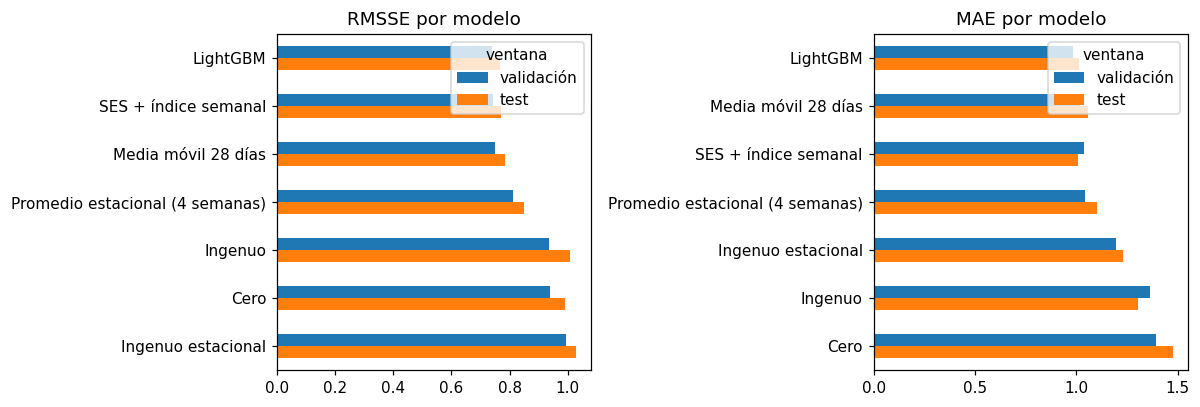

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metrica in zip(axes, ["RMSSE", "MAE"]):
    tabla[metrica].sort_values("validación").plot.barh(ax=ax)
    ax.set_title(metrica + " por modelo")
    ax.set_ylabel("")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Análisis del modelo

### 6.1 Qué variables usa

Importancia por **ganancia**: cuánto reduce el error cada variable, sumando todos los árboles, expresada como proporción del total. Muestra qué información usa el modelo, no que esa variable *cause* las ventas.

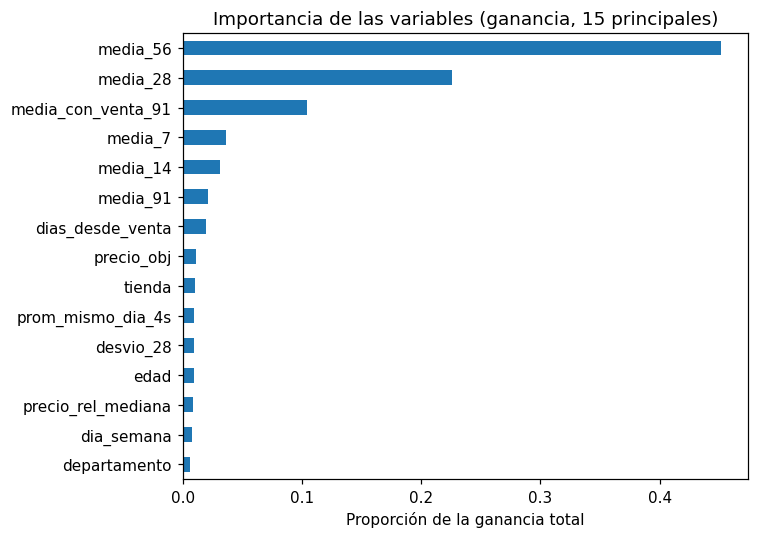

,importancia
media_56,0.452
media_28,0.226
media_con_venta_91,0.105
media_7,0.036
media_14,0.031
media_91,0.021
dias_desde_venta,0.020
precio_obj,0.011
tienda,0.010
prom_mismo_dia_4s,0.009


In [12]:
imp = pd.Series(modelo_final.feature_importances_, index=X_fin.columns)
imp = (imp / imp.sum()).sort_values(ascending=False)

ax = imp.head(15).iloc[::-1].plot.barh(figsize=(7, 5))
ax.set_title("Importancia de las variables (ganancia, 15 principales)")
ax.set_xlabel("Proporción de la ganancia total")
plt.tight_layout()
plt.show()

imp.head(15).round(3).to_frame("importancia")

### 6.2 Resultados según el tipo de demanda (validación)

Las series se clasifican con el historial anterior al origen. Se compara LightGBM con la media móvil y con el modelo estadístico del notebook 02.

In [13]:
wday = calendario["wday"].to_numpy() - 1
categorias = muestra["cat_id"].astype(str).to_numpy()
pred_ma = pronostico_media_movil(Y_train_val, H)
pred_ses = ses_semanal(Y_train_val, H, wday[:o_val], wday[o_val:o_val + H], categorias)[0]

tipo = clasificar_demanda(Y_train_val)["tipo"].to_numpy()
modelos_tipo = {"Media móvil 28 días": pred_ma, "SES + índice semanal": pred_ses, "LightGBM": preds_val[mejor]}
filas_t = []
for nombre, p in modelos_tipo.items():
    r = rmsse(Y_train_val, Y_real_val, p)
    a = np.abs(Y_real_val - p).mean(axis=1)
    g = pd.DataFrame({"tipo": tipo, "RMSSE": r, "MAE": a}).groupby("tipo").agg(RMSSE=("RMSSE", "mean"), MAE=("MAE", "mean"), series=("MAE", "size"))
    g["modelo"] = nombre
    filas_t.append(g.reset_index())
por_tipo = pd.concat(filas_t, ignore_index=True)

print("Series por tipo:", por_tipo.groupby("tipo")["series"].first().to_dict())
print()
print("RMSSE por tipo de demanda:")
por_tipo.pivot(index="modelo", columns="tipo", values="RMSSE").round(3)

Series por tipo: {'errática': 19, 'intermitente': 434, 'irregular': 121, 'suave': 26}

RMSSE por tipo de demanda:


tipo,errática,intermitente,irregular,suave
modelo,,,,
LightGBM,0.805,0.757,0.688,0.651
Media móvil 28 días,0.912,0.765,0.688,0.689
SES + índice semanal,0.877,0.756,0.686,0.668


In [14]:
print("MAE por tipo de demanda:")
por_tipo.pivot(index="modelo", columns="tipo", values="MAE").round(3)

MAE por tipo de demanda:


tipo,errática,intermitente,irregular,suave
modelo,,,,
LightGBM,3.472,0.704,1.381,1.969
Media móvil 28 días,4.011,0.726,1.363,2.142
SES + índice semanal,4.031,0.742,1.383,2.133


### 6.3 Error según el día del horizonte

MAE promedio de cada día del horizonte (1 a 28 días después del origen), en la ventana de validación. Muestra si el modelo pierde precisión a medida que se aleja del origen.

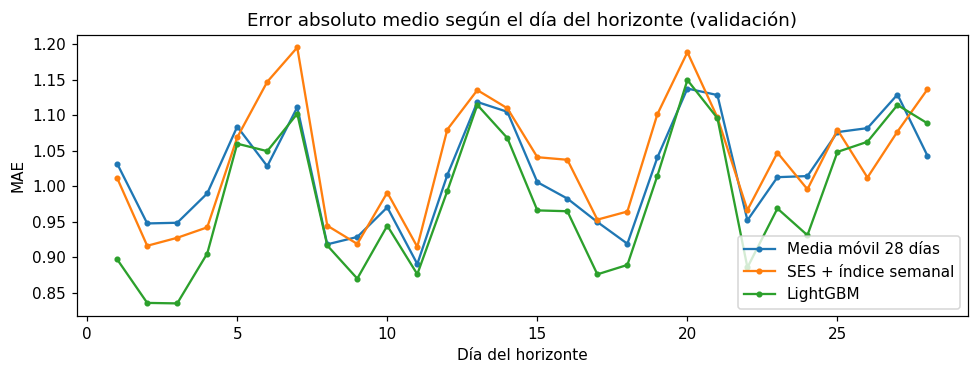

In [15]:
mae_k = {nombre: np.abs(Y_real_val - p).mean(axis=0) for nombre, p in modelos_tipo.items()}
fig, ax = plt.subplots(figsize=(9, 3.5))
for nombre, v in mae_k.items():
    ax.plot(np.arange(1, H + 1), v, marker="o", markersize=3, label=nombre)
ax.set_xlabel("Día del horizonte")
ax.set_ylabel("MAE")
ax.set_title("Error absoluto medio según el día del horizonte (validación)")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Guardar resultados

In [16]:
os.makedirs(os.path.join(ROOT, "models"), exist_ok=True)
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)

modelo_final.booster_.save_model(os.path.join(ROOT, "models", "lightgbm_final.txt"))
tabla_exp.to_csv(os.path.join(ROOT, "reports", "lightgbm_experimentos.csv"))
np.savez(os.path.join(ROOT, "reports", "predicciones_lightgbm.npz"),
         validacion=preds_val[mejor], test=pred_test, ids=muestra["id"].astype(str).to_numpy().astype("U"))
print("Guardados: modelo, tabla de experimentos y predicciones")

Guardados: modelo, tabla de experimentos y predicciones


## 8. Conclusiones

- **Pipeline sin fuga:** la prueba anti-fuga da `True`: las variables no cambian al alterar las ventas posteriores al origen. Cada origen aporta 16.800 filas (600 series × 28 días) y el modelo final se entrenó con 868.588 filas. Cada configuración tardó entre 3 y 13 segundos, por lo que el cómputo no fue una limitación.
- **Objetivo:** con exponentes de Tweedie de 1,1, 1,3 y 1,5, el RMSSE en validación es 0,745, 0,742 y 0,741 y el MAE es 0,995, 0,984 y 0,980. El error cuadrático da 0,750 y 1,010, y se detuvo en solo 97 árboles. Tweedie mejora al error cuadrático en alrededor de 1 % en RMSSE y 3 % en MAE; entre los tres exponentes la diferencia es menor a 1 %. El mejor es el más alto de los probados (1,5), por lo que no se sabe si valores mayores mejorarían.
- **Complejidad:** 15, 31 y 63 hojas por árbol dan un RMSSE de 0,740, 0,741 y 0,741 (509, 403 y 311 árboles). La diferencia es irrelevante: se eligió la de 15 hojas por tener el menor RMSSE, pero cualquiera de las tres habría sido equivalente.
- **Comparación en validación:** LightGBM obtiene RMSSE de 0,740 y MAE de 0,983, contra 0,742 y 1,036 de SES + índice semanal y 0,751 y 1,020 de la media móvil. La ventaja en RMSSE sobre SES es de 0,3 %; la de MAE, de 5 %. Como la configuración se eligió entre seis en esta misma ventana, estas cifras son algo optimistas.
- **Test (evaluado una sola vez):** LightGBM obtiene RMSSE de 0,768 y MAE de 1,011, contra 0,769 y 1,008 de SES: **un empate técnico**. Frente a la media móvil (0,782 y 1,059) la mejora es de 1,8 % en RMSSE y 4,5 % en MAE. La ventaja de MAE sobre SES que había en validación no se sostiene en test. En esta muestra no hay evidencia de que LightGBM supere al modelo estadístico simple: diferencias de menos de 1 % no se pueden distinguir del ruido con una ventana de 28 días y 600 series (el notebook 04 lo cuantifica con intervalos de confianza).
- **Variables más usadas:** `media_56` (45 %), `media_28` (23 %) y `media_con_venta_91` (11 %) suman el 78 % de la ganancia, y todas las variables de nivel de ventas juntas, alrededor del 87 %. El modelo se apoya sobre todo en el nivel reciente de ventas, como lo hace la media móvil. El día de la semana pesa 0,7 %, el precio del día 1,1 % y la antigüedad de la serie 0,9 %; los días SNAP, los eventos y el horizonte no están entre las 15 principales. La importancia por ganancia no mide causalidad, y con promedios muy correlacionados entre sí (`media_14`, `media_28`, `media_56`) el reparto entre ellos es en parte arbitrario.
- **Por tipo de demanda (validación):** hay 19 series erráticas, 434 intermitentes, 121 irregulares y 26 suaves. LightGBM tiene menor RMSSE que SES en las erráticas (0,805 contra 0,877) y las suaves (0,651 contra 0,668), y empata en las intermitentes (0,757 contra 0,756) y las irregulares (0,688 contra 0,686). En MAE mejora en erráticas (3,47 contra 4,03), suaves (1,97 contra 2,13) e intermitentes (0,704 contra 0,742), y queda algo peor que la media móvil en irregulares (1,381 contra 1,363). De la mejora total de MAE sobre SES en validación (0,053), alrededor del 52 % proviene de las intermitentes, el 34 % de las erráticas y el 13 % de las suaves. Las erráticas y las suaves son solo 45 series, por lo que esas diferencias son inestables.
- **Error según el día del horizonte (validación):** según el gráfico, el MAE de los tres modelos sube y baja de forma parecida, con máximos y mínimos en los mismos días y máximos separados por 7 días, lo que refleja la estacionalidad semanal: los días de más ventas tienen errores absolutos mayores en unidades. LightGBM tiene el menor error en casi todos los días, la media móvil queda en el medio y SES, por encima de las dos.
- **Interpretación (hipótesis sin verificar):** la demanda diaria de cada producto es muy ruidosa, y buena parte del error sería irreducible; el nivel reciente de ventas y la estacionalidad semanal, que ya captura SES, explicarían casi todo lo predecible. Los precios cambian en pocas semanas y las ventanas de evaluación tienen pocos eventos, lo que limita el aporte de esas variables.
- **Limitaciones:** una sola ventana por etapa y sin intervalos de confianza; 600 series de las 30.490; configuración elegida entre seis, varias con diferencias dentro del ruido; no se exploraron exponentes de Tweedie mayores a 1,5 ni otros hiperparámetros (tasa de aprendizaje, regularización); y las variables se diseñaron una sola vez.
- **Próximo paso:** el notebook 04 entrena una red neuronal en Keras y compara todos los modelos, con intervalos de confianza por bootstrap entre series para cuantificar si las diferencias son reales.